# Task resources, retries and scheduling options

Per-call .options(): CPU and memory requests, automatic retries on application errors, a task name for the dashboard, the SPREAD scheduling strategy and a timeout on ray.get.

**When to use it.** When tasks need specific resources, can fail transiently, or should be spread across nodes.

The picture below is the graph drawn in Eugo's visual Ray builder, and the cell under *Generated code* is the Ray code the builder produced from it. The code is plain Ray: it runs without the builder.

[Back to the gallery](../README.md) · Tested with Ray 2.55.1

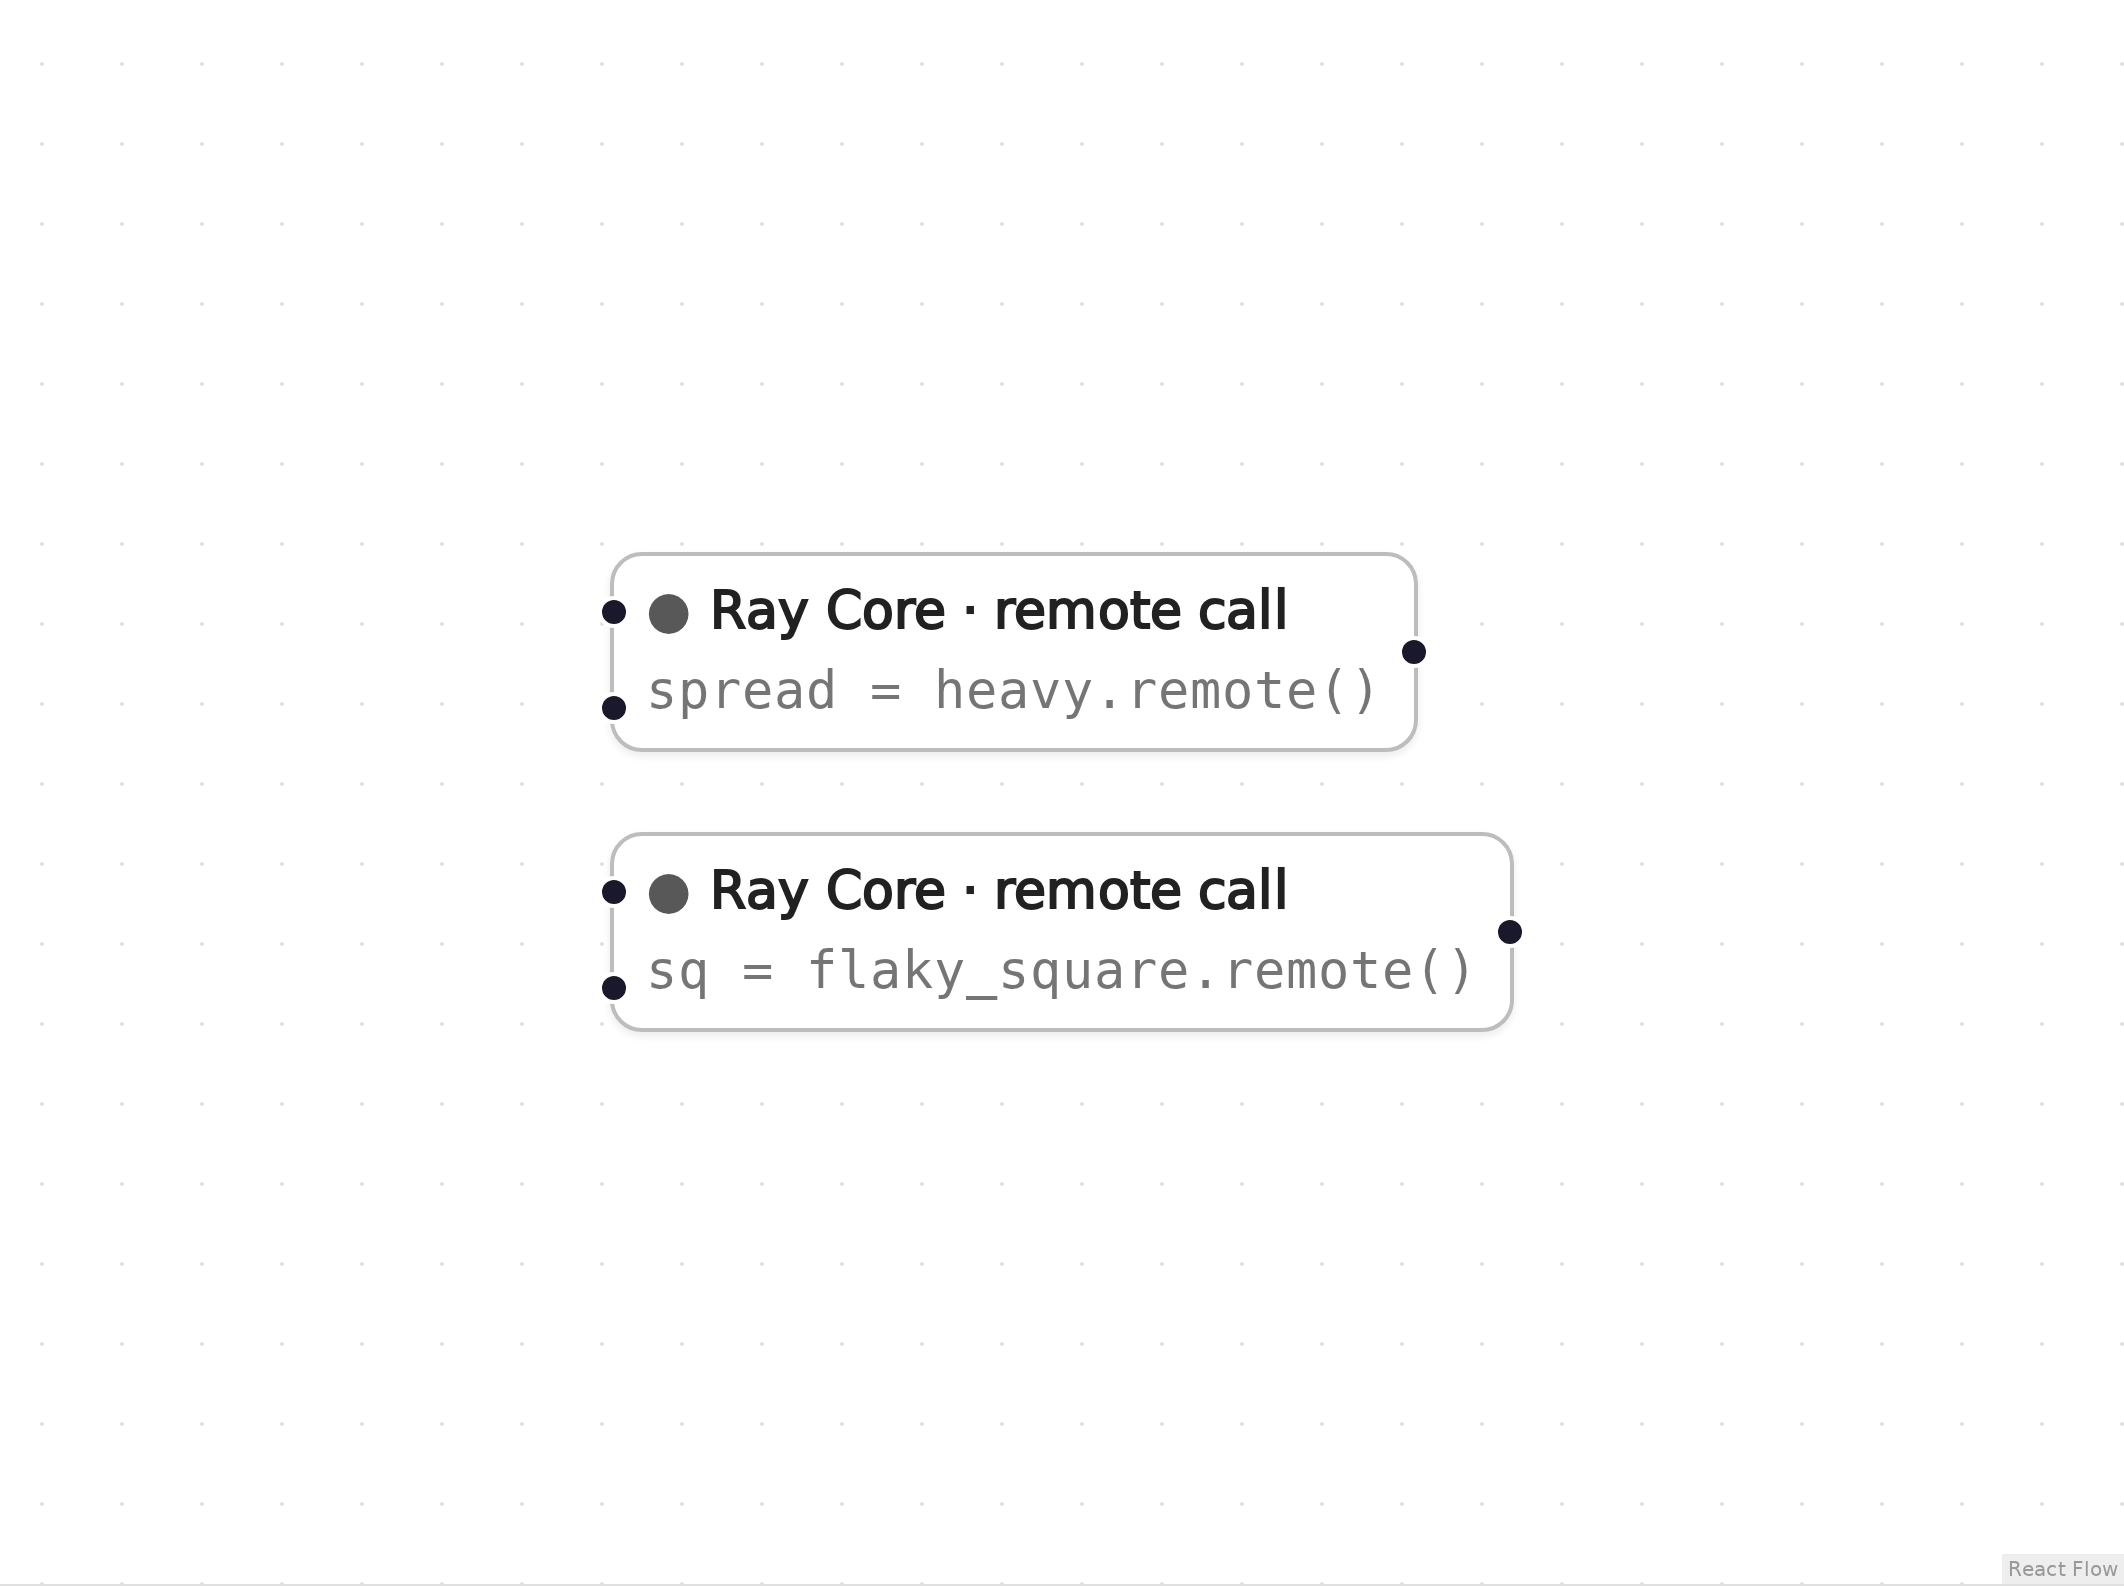

*The graph in Eugo's visual Ray builder.*

## Setup

Start a local Ray instance. The options keep the notebook quiet: no dashboard, and worker logs stay out of the notebook. Ray is capped at four CPUs so the example behaves the same on any machine. The generated code below only calls `ray.init()` when Ray is not running yet, so it reuses this instance.

In [1]:
import ray
ray.init(include_dashboard=False, log_to_driver=False, logging_level="ERROR", num_cpus=4)

RayContext(dashboard_url='', python_version='3.12.3', ray_version='2.55.1', ray_commit='237c2455ebb1ea15a32dd9e1fdeb2d617badc37f')

## User functions

The nodes in the graph call these ordinary Python functions and classes. In the builder you write them in a normal notebook cell, and the generated code refers to them by name.

In [2]:
import os
import tempfile

# A marker file, unique to this run, makes the first attempt fail and the retry succeed.
_FIRST_ATTEMPT_MARKER = os.path.join(tempfile.mkdtemp(), "attempted")


def flaky_square(x):
    if not os.path.exists(_FIRST_ATTEMPT_MARKER):
        open(_FIRST_ATTEMPT_MARKER, "w").close()
        raise RuntimeError("transient failure on the first attempt")
    return x * x


def heavy(n):
    return sum(i * i for i in range(n * 1000))

## Generated code

This is the cell the visual builder generated from the graph above.

In [3]:
# Generated with Eugo's visual Ray builder

import ray

if not ray.is_initialized():
    ray.init()

_n1 = ray.remote(flaky_square).options(num_cpus=1, max_retries=3, retry_exceptions=True, name="square_seven").remote(7)
sq = ray.get(_n1)
_n2 = ray.remote(heavy).options(num_cpus=0.5, memory=104857600, scheduling_strategy="SPREAD").remote(3)
spread = ray.get(_n2, timeout=60)

## Check the result

The cell below checks that the generated code did what the graph describes.

In [4]:
assert sq == 49, sq
assert os.path.exists(_FIRST_ATTEMPT_MARKER), "the first attempt never ran"
assert spread == sum(i * i for i in range(3000)), spread
print("sq =", sq, "(succeeded on retry)")
print("spread =", spread)

sq = 49 (succeeded on retry)
spread = 8995500500


## How the graph maps to the code

Each step names a node in the picture, the lines of the generated cell it produced, and what those lines do. The node id (for example `n1`) is also the suffix of the variable that holds the node's result.

**Setup** (lines 1, 3 and 5–6)

```python
# Generated with Eugo's visual Ray builder
...
import ray
...
if not ray.is_initialized():
    ray.init()
```

The first line marks the cell as generated. The builder then adds an import for every Ray API the graph uses and a guarded ray.init(), so re-running the cell reuses the running cluster.

**Remote task** (node `n1`, lines 8–9)

```python
_n1 = ray.remote(flaky_square).options(num_cpus=1, max_retries=3, retry_exceptions=True, name="square_seven").remote(7)
sq = ray.get(_n1)
```

num_cpus=1 reserves a CPU; max_retries=3 with retry_exceptions=True re-runs the task when it raises, so the first failure is absorbed; name labels it in the dashboard.

**Remote task** (node `n2`, lines 10–11)

```python
_n2 = ray.remote(heavy).options(num_cpus=0.5, memory=104857600, scheduling_strategy="SPREAD").remote(3)
spread = ray.get(_n2, timeout=60)
```

Half a CPU and 100 MiB of memory, scheduled with the SPREAD strategy. The ray.get timeout raises GetTimeoutError instead of waiting forever.

## Clean up

Shut down Ray, so the next notebook starts fresh.

In [5]:
ray.shutdown()